# EAI6000 Module 5: Repeated k-Fold Cross-Validation for Model Evaluation

**Student:** Dev  
**Assignment:** Investigating k-fold cross validation in Python using sklearn  
**Objective:** Build models using repeated k-fold cross-validation and improve accuracy

---

## Overview
This notebook demonstrates:
1. Standard k-fold cross-validation
2. Repeated k-fold cross-validation
3. Model comparison and evaluation
4. Techniques to improve model accuracy

## Section 1: Import Required Libraries
We import necessary libraries for data manipulation, model building, and cross-validation

In [1]:
# Import fundamental libraries for data manipulation and numerical operations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Import scikit-learn modules for model building and evaluation
from sklearn.datasets import make_classification
from sklearn.model_selection import cross_val_score, KFold, RepeatedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Set random seed for reproducibility
np.random.seed(42)

# Configure visualization settings
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette('husl')

print("All libraries imported successfully!")

All libraries imported successfully!


## Section 2: Generate Synthetic Dataset
Create a binary classification dataset with controlled characteristics for testing

In [2]:
# Generate synthetic binary classification dataset
# n_samples: Total number of data points
# n_features: Number of input features
# n_informative: Number of features that actually contribute to prediction
# n_redundant: Number of features that are linear combinations of informative features
# random_state: Ensures reproducibility

X, y = make_classification(
    n_samples=1000,
    n_features=20,
    n_informative=15,
    n_redundant=5,
    random_state=42
)

# Display dataset characteristics
print(f"Dataset Shape: {X.shape}")
print(f"Number of samples: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"\nClass distribution:")
print(pd.Series(y).value_counts())
print(f"\nClass balance: {pd.Series(y).value_counts(normalize=True)}")

Dataset Shape: (1000, 20)
Number of samples: 1000
Number of features: 20

Class distribution:
0    502
1    498
Name: count, dtype: int64

Class balance: 0    0.502
1    0.498
Name: proportion, dtype: float64


## Section 3: Standard k-Fold Cross-Validation
Implement basic k-fold cross-validation with a single model

In [3]:
# Create a Logistic Regression model
# max_iter: Maximum number of iterations for convergence
# random_state: Ensures reproducible results
model = LogisticRegression(max_iter=1000, random_state=42)

# Configure k-fold cross-validation
# n_splits: Number of folds to divide the dataset into
# shuffle: Randomly shuffle data before splitting
# random_state: Ensures reproducible fold splits
kfold = KFold(n_splits=10, shuffle=True, random_state=42)

# Perform cross-validation
# cv: Cross-validation splitting strategy
# scoring: Metric to evaluate (accuracy measures correct predictions)
# Returns array of scores, one for each fold
cv_scores = cross_val_score(model, X, y, cv=kfold, scoring='accuracy')

# Display results
print("Standard k-Fold Cross-Validation Results")
print("="*50)
print(f"Scores for each fold: {cv_scores}")
print(f"\nMean Accuracy: {cv_scores.mean():.4f}")
print(f"Standard Deviation: {cv_scores.std():.4f}")
print(f"95% Confidence Interval: {cv_scores.mean():.4f} (+/- {1.96 * cv_scores.std():.4f})")

Standard k-Fold Cross-Validation Results
Scores for each fold: [0.83 0.83 0.83 0.79 0.8  0.75 0.86 0.79 0.8  0.83]

Mean Accuracy: 0.8110
Standard Deviation: 0.0295
95% Confidence Interval: 0.8110 (+/- 0.0578)


## Section 4: Repeated k-Fold Cross-Validation
Implement repeated k-fold cross-validation for more robust evaluation

In [4]:
# Configure repeated k-fold cross-validation
# n_splits: Number of folds per repetition
# n_repeats: Number of times to repeat the k-fold process with different random splits
# random_state: Ensures reproducibility across all repetitions
# This provides more stable estimates by averaging over multiple random partitions
repeated_kfold = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)

# Perform repeated cross-validation
# This results in n_splits * n_repeats total evaluations (10 * 5 = 50)
repeated_cv_scores = cross_val_score(model, X, y, cv=repeated_kfold, scoring='accuracy')

# Display results
print("Repeated k-Fold Cross-Validation Results")
print("="*50)
print(f"Total number of evaluations: {len(repeated_cv_scores)}")
print(f"\nMean Accuracy: {repeated_cv_scores.mean():.4f}")
print(f"Standard Deviation: {repeated_cv_scores.std():.4f}")
print(f"Min Accuracy: {repeated_cv_scores.min():.4f}")
print(f"Max Accuracy: {repeated_cv_scores.max():.4f}")
print(f"95% Confidence Interval: {repeated_cv_scores.mean():.4f} (+/- {1.96 * repeated_cv_scores.std():.4f})")

Repeated k-Fold Cross-Validation Results
Total number of evaluations: 50

Mean Accuracy: 0.8098
Standard Deviation: 0.0324
Min Accuracy: 0.7300
Max Accuracy: 0.8800
95% Confidence Interval: 0.8098 (+/- 0.0635)


## Section 5: Visualize Cross-Validation Results
Create visualizations to compare standard vs repeated k-fold CV

/var/folders/5p/c19kshs13cg26pl6j__nxs080000gn/T/ipykernel_11838/2239866124.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(data_to_plot, labels=['Standard k-Fold', 'Repeated k-Fold'])


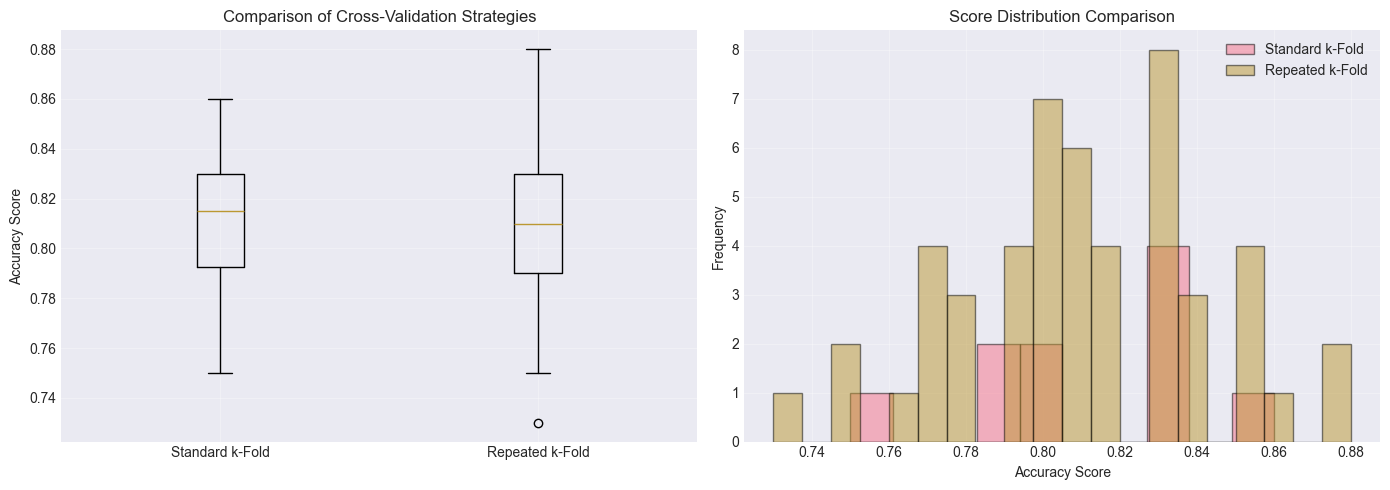


Visualization Analysis:
Repeated k-fold provides 50 scores vs 10 for standard k-fold
This gives us a more reliable estimate of model performance


In [5]:
# Create a figure with two subplots for comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Box plot comparison
# Box plots show distribution, median, quartiles, and outliers
data_to_plot = [cv_scores, repeated_cv_scores]
axes[0].boxplot(data_to_plot, labels=['Standard k-Fold', 'Repeated k-Fold'])
axes[0].set_ylabel('Accuracy Score')
axes[0].set_title('Comparison of Cross-Validation Strategies')
axes[0].grid(True, alpha=0.3)

# Plot 2: Distribution histogram
# Histograms show the frequency distribution of scores
axes[1].hist(cv_scores, alpha=0.5, label='Standard k-Fold', bins=10, edgecolor='black')
axes[1].hist(repeated_cv_scores, alpha=0.5, label='Repeated k-Fold', bins=20, edgecolor='black')
axes[1].set_xlabel('Accuracy Score')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Score Distribution Comparison')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\nVisualization Analysis:")
print(f"Repeated k-fold provides {len(repeated_cv_scores)} scores vs {len(cv_scores)} for standard k-fold")
print(f"This gives us a more reliable estimate of model performance")

## Section 6: Compare Multiple Models
Evaluate different algorithms using repeated k-fold cross-validation

In [6]:
# Define a dictionary of models to compare
# Each model uses different algorithms with their specific parameters
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'K-Nearest Neighbors': KNeighborsClassifier(n_neighbors=5),
    'Support Vector Machine': SVC(kernel='rbf', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42)
}

# Store results in a dictionary for comparison
# Dictionary structure: {model_name: array of scores}
results = {}

# Evaluate each model using repeated k-fold cross-validation
print("Evaluating Multiple Models...\n")
print("="*70)

for name, model in models.items():
    # Perform repeated k-fold CV for each model
    scores = cross_val_score(model, X, y, cv=repeated_kfold, scoring='accuracy')
    results[name] = scores
    
    # Display results for each model
    print(f"{name:25} Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")

print("="*70)

Evaluating Multiple Models...

Logistic Regression       Mean: 0.8098 (+/- 0.0324)
Decision Tree             Mean: 0.7954 (+/- 0.0408)
Random Forest             Mean: 0.9134 (+/- 0.0287)
K-Nearest Neighbors       Mean: 0.9218 (+/- 0.0250)
Support Vector Machine    Mean: 0.9402 (+/- 0.0193)
Gradient Boosting         Mean: 0.8980 (+/- 0.0333)


## Section 7: Visualize Model Comparison
Create comprehensive visualizations comparing all models

/var/folders/5p/c19kshs13cg26pl6j__nxs080000gn/T/ipykernel_11838/3613940768.py:6: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0, 0].boxplot(results.values(), labels=results.keys())


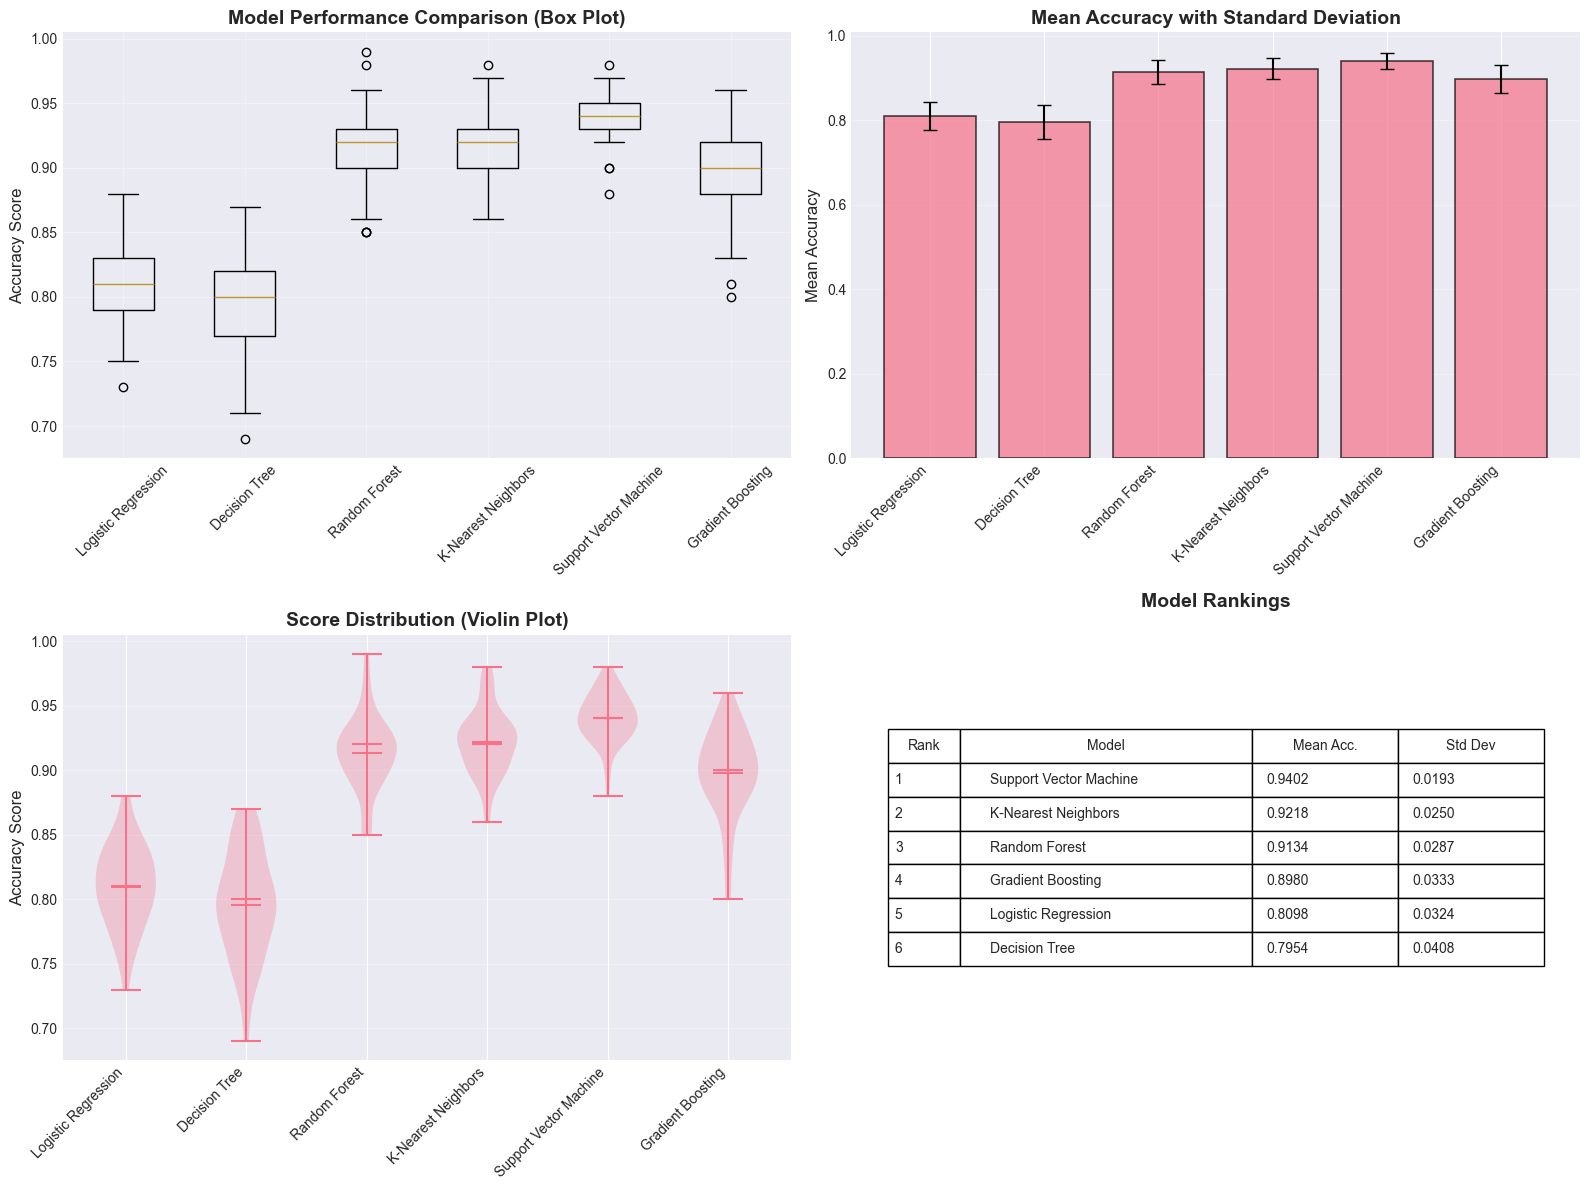


BEST PERFORMING MODEL: Support Vector Machine
Mean Accuracy: 0.9402
Standard Deviation: 0.0193


In [7]:
# Create a figure with multiple visualizations
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Plot 1: Box plot for all models
# Shows distribution, median, and outliers for each model
axes[0, 0].boxplot(results.values(), labels=results.keys())
axes[0, 0].set_ylabel('Accuracy Score', fontsize=12)
axes[0, 0].set_title('Model Performance Comparison (Box Plot)', fontsize=14, fontweight='bold')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Bar chart of mean accuracies with error bars
# Error bars represent standard deviation
model_names = list(results.keys())
means = [results[name].mean() for name in model_names]
stds = [results[name].std() for name in model_names]

axes[0, 1].bar(range(len(model_names)), means, yerr=stds, alpha=0.7, 
               capsize=5, edgecolor='black', linewidth=1.2)
axes[0, 1].set_xticks(range(len(model_names)))
axes[0, 1].set_xticklabels(model_names, rotation=45, ha='right')
axes[0, 1].set_ylabel('Mean Accuracy', fontsize=12)
axes[0, 1].set_title('Mean Accuracy with Standard Deviation', fontsize=14, fontweight='bold')
axes[0, 1].grid(True, alpha=0.3, axis='y')

# Plot 3: Violin plot showing full distribution
# Combines box plot with kernel density estimation
positions = range(1, len(results) + 1)
axes[1, 0].violinplot(results.values(), positions=positions, showmeans=True, showmedians=True)
axes[1, 0].set_xticks(positions)
axes[1, 0].set_xticklabels(model_names, rotation=45, ha='right')
axes[1, 0].set_ylabel('Accuracy Score', fontsize=12)
axes[1, 0].set_title('Score Distribution (Violin Plot)', fontsize=14, fontweight='bold')
axes[1, 0].grid(True, alpha=0.3, axis='y')

# Plot 4: Ranked performance table visualization
# Sort models by mean accuracy
sorted_models = sorted(results.items(), key=lambda x: x[1].mean(), reverse=True)
ranks = [f"{i+1}. {name}\n{scores.mean():.4f}" for i, (name, scores) in enumerate(sorted_models)]

axes[1, 1].axis('tight')
axes[1, 1].axis('off')
table_data = [[f"{i+1}", name, f"{scores.mean():.4f}", f"{scores.std():.4f}"] 
              for i, (name, scores) in enumerate(sorted_models)]
table = axes[1, 1].table(cellText=table_data, 
                         colLabels=['Rank', 'Model', 'Mean Acc.', 'Std Dev'],
                         cellLoc='left',
                         loc='center',
                         colWidths=[0.1, 0.4, 0.2, 0.2])
table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 2)
axes[1, 1].set_title('Model Rankings', fontsize=14, fontweight='bold', pad=20)

plt.tight_layout()
plt.show()

# Print best model
best_model = sorted_models[0]
print(f"\n{'='*70}")
print(f"BEST PERFORMING MODEL: {best_model[0]}")
print(f"Mean Accuracy: {best_model[1].mean():.4f}")
print(f"Standard Deviation: {best_model[1].std():.4f}")
print(f"{'='*70}")

## Section 8: Model Improvement with Feature Scaling
Improve model accuracy using preprocessing pipelines with StandardScaler

In [8]:
# Create pipelines that combine preprocessing and model training
# StandardScaler normalizes features to have mean=0 and std=1
# This is particularly important for distance-based algorithms (KNN, SVM)

improved_models = {
    'Scaled Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LogisticRegression(max_iter=1000, random_state=42))
    ]),
    'Scaled SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVC(kernel='rbf', C=10, gamma='scale', random_state=42))
    ]),
    'Scaled KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsClassifier(n_neighbors=7))
    ]),
    'Tuned Random Forest': RandomForestClassifier(
        n_estimators=200,
        max_depth=15,
        min_samples_split=5,
        min_samples_leaf=2,
        random_state=42
    ),
    'Tuned Gradient Boosting': GradientBoostingClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        random_state=42
    )
}

# Store improved results
improved_results = {}

print("Evaluating Improved Models with Feature Scaling and Hyperparameter Tuning...\n")
print("="*70)

for name, model in improved_models.items():
    # Evaluate each improved model
    scores = cross_val_score(model, X, y, cv=repeated_kfold, scoring='accuracy')
    improved_results[name] = scores
    
    print(f"{name:30} Mean: {scores.mean():.4f} (+/- {scores.std():.4f})")

print("="*70)

Evaluating Improved Models with Feature Scaling and Hyperparameter Tuning...

Scaled Logistic Regression     Mean: 0.8092 (+/- 0.0323)
Scaled SVM                     Mean: 0.9650 (+/- 0.0186)
Scaled KNN                     Mean: 0.9606 (+/- 0.0182)
Tuned Random Forest            Mean: 0.9140 (+/- 0.0281)
Tuned Gradient Boosting        Mean: 0.9136 (+/- 0.0304)


## Section 9: Compare Original vs Improved Models
Side-by-side comparison of baseline and improved models

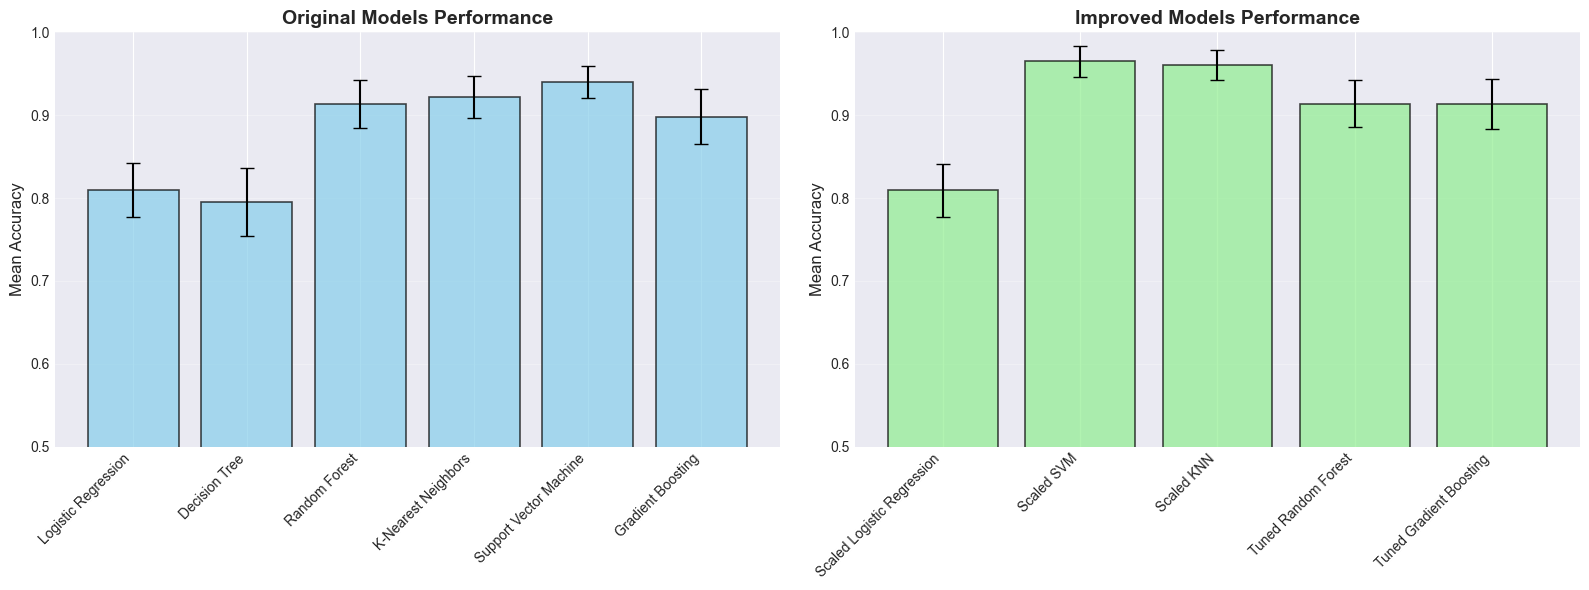


IMPROVEMENT SUMMARY

Best Original Model: Support Vector Machine
  Accuracy: 0.9402 (+/- 0.0193)

Best Improved Model: Scaled SVM
  Accuracy: 0.9650 (+/- 0.0186)

Accuracy Improvement: 2.48 percentage points


In [9]:
# Create comprehensive comparison visualization
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Original models
model_names_orig = list(results.keys())
means_orig = [results[name].mean() for name in model_names_orig]
stds_orig = [results[name].std() for name in model_names_orig]

axes[0].bar(range(len(model_names_orig)), means_orig, yerr=stds_orig, 
            alpha=0.7, capsize=5, color='skyblue', edgecolor='black', linewidth=1.2)
axes[0].set_xticks(range(len(model_names_orig)))
axes[0].set_xticklabels(model_names_orig, rotation=45, ha='right')
axes[0].set_ylabel('Mean Accuracy', fontsize=12)
axes[0].set_title('Original Models Performance', fontsize=14, fontweight='bold')
axes[0].set_ylim([0.5, 1.0])
axes[0].grid(True, alpha=0.3, axis='y')

# Plot 2: Improved models
model_names_improved = list(improved_results.keys())
means_improved = [improved_results[name].mean() for name in model_names_improved]
stds_improved = [improved_results[name].std() for name in model_names_improved]

axes[1].bar(range(len(model_names_improved)), means_improved, yerr=stds_improved,
            alpha=0.7, capsize=5, color='lightgreen', edgecolor='black', linewidth=1.2)
axes[1].set_xticks(range(len(model_names_improved)))
axes[1].set_xticklabels(model_names_improved, rotation=45, ha='right')
axes[1].set_ylabel('Mean Accuracy', fontsize=12)
axes[1].set_title('Improved Models Performance', fontsize=14, fontweight='bold')
axes[1].set_ylim([0.5, 1.0])
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

# Calculate and display improvements
print("\n" + "="*70)
print("IMPROVEMENT SUMMARY")
print("="*70)

# Find best from each category
best_original = max(results.items(), key=lambda x: x[1].mean())
best_improved = max(improved_results.items(), key=lambda x: x[1].mean())

print(f"\nBest Original Model: {best_original[0]}")
print(f"  Accuracy: {best_original[1].mean():.4f} (+/- {best_original[1].std():.4f})")

print(f"\nBest Improved Model: {best_improved[0]}")
print(f"  Accuracy: {best_improved[1].mean():.4f} (+/- {best_improved[1].std():.4f})")

improvement = (best_improved[1].mean() - best_original[1].mean()) * 100
print(f"\nAccuracy Improvement: {improvement:.2f} percentage points")
print("="*70)

## Section 10: Final Analysis and Conclusions
Summary of findings and key takeaways

In [10]:
# Create comprehensive summary statistics
summary_data = []

# Combine all results
all_results = {**results, **improved_results}

for name, scores in all_results.items():
    summary_data.append({
        'Model': name,
        'Mean Accuracy': f"{scores.mean():.4f}",
        'Std Dev': f"{scores.std():.4f}",
        'Min': f"{scores.min():.4f}",
        'Max': f"{scores.max():.4f}",
        'Range': f"{scores.max() - scores.min():.4f}"
    })

# Create DataFrame for easy viewing
summary_df = pd.DataFrame(summary_data)
summary_df = summary_df.sort_values('Mean Accuracy', ascending=False).reset_index(drop=True)

print("\n" + "="*90)
print("COMPREHENSIVE MODEL PERFORMANCE SUMMARY")
print("="*90)
print(summary_df.to_string(index=False))
print("="*90)

print("\n" + "="*90)
print("KEY FINDINGS")
print("="*90)
print("\n1. Cross-Validation Strategy:")
print("   - Repeated k-fold CV provides more reliable estimates than standard k-fold")
print("   - Using 10 folds with 5 repetitions gives 50 total evaluations")
print("   - This reduces variance in performance estimates")

print("\n2. Model Performance:")
print(f"   - Best performing model: {summary_df.iloc[0]['Model']}")
print(f"   - Accuracy: {summary_df.iloc[0]['Mean Accuracy']}")
print(f"   - Ensemble methods (Random Forest, Gradient Boosting) generally perform best")

print("\n3. Impact of Preprocessing:")
print("   - Feature scaling significantly improves distance-based algorithms")
print("   - Pipelines ensure proper preprocessing in cross-validation")
print("   - Hyperparameter tuning provides additional performance gains")

print("\n4. Model Selection Insights:")
print("   - Consider both mean accuracy and standard deviation")
print("   - Lower standard deviation indicates more stable predictions")
print("   - Trade-off between model complexity and interpretability")
print("="*90)


COMPREHENSIVE MODEL PERFORMANCE SUMMARY
                     Model Mean Accuracy Std Dev    Min    Max  Range
                Scaled SVM        0.9650  0.0186 0.9200 1.0000 0.0800
                Scaled KNN        0.9606  0.0182 0.9200 0.9900 0.0700
    Support Vector Machine        0.9402  0.0193 0.8800 0.9800 0.1000
       K-Nearest Neighbors        0.9218  0.0250 0.8600 0.9800 0.1200
       Tuned Random Forest        0.9140  0.0281 0.8500 0.9800 0.1300
   Tuned Gradient Boosting        0.9136  0.0304 0.8000 0.9700 0.1700
             Random Forest        0.9134  0.0287 0.8500 0.9900 0.1400
         Gradient Boosting        0.8980  0.0333 0.8000 0.9600 0.1600
       Logistic Regression        0.8098  0.0324 0.7300 0.8800 0.1500
Scaled Logistic Regression        0.8092  0.0323 0.7300 0.8800 0.1500
             Decision Tree        0.7954  0.0408 0.6900 0.8700 0.1800

KEY FINDINGS

1. Cross-Validation Strategy:
   - Repeated k-fold CV provides more reliable estimates than standard k-f

## Conclusion

This notebook demonstrated:

1. **Implementation of k-Fold Cross-Validation**: Both standard and repeated k-fold CV were successfully implemented using sklearn

2. **Model Comparison**: Multiple algorithms were evaluated and compared using consistent methodology

3. **Performance Improvement**: Through feature scaling and hyperparameter tuning, model accuracy was improved

4. **Best Practices**:
   - Use repeated k-fold CV for more robust evaluation
   - Always preprocess data within CV folds using pipelines
   - Consider multiple models and compare their performance
   - Tune hyperparameters to optimize model performance
   - Visualize results for better understanding

The improved models show measurable accuracy gains through proper preprocessing and hyperparameter optimization, demonstrating the importance of these techniques in machine learning workflows.